## Machine Learning CA1

### CCT HDIP Data Analytics September 2026

##### Student: Jing Liang

Project overview



## 0. Import Libraries

In [62]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kruskal


## 1. Data Preparation

#### 1.1 Load the dataset

The original data was provided as an Excel file containing three sheets: Description, Data and Raw Data. The raw data sheet was re-saved in .csv format as "CTG_raw_data.csv".

In [2]:
df_original = pd.read_csv('CTG_raw_data.csv')

#### 1.2 Initial data inspection

In [3]:
df_original.head(5)

,FileName,Date,SegFile,b,e,LBE,LB,AC,FM,UC,...,C,D,E,AD,DE,LD,FS,SUSP,CLASS,NSP
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Variab10.txt,01/12/1996,CTG0001.txt,240.0,357.0,120.0,120.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,9.0,2.0
2,Fmcs_1.txt,03/05/1996,CTG0002.txt,5.0,632.0,132.0,132.0,4.0,0.0,4.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,6.0,1.0
3,Fmcs_1.txt,03/05/1996,CTG0003.txt,177.0,779.0,133.0,133.0,2.0,0.0,5.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,6.0,1.0
4,Fmcs_1.txt,03/05/1996,CTG0004.txt,411.0,1192.0,134.0,134.0,2.0,0.0,6.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,6.0,1.0


In [4]:
df_original.tail(5)

,FileName,Date,SegFile,b,e,LBE,LB,AC,FM,UC,...,C,D,E,AD,DE,LD,FS,SUSP,CLASS,NSP
2125,S8001045.dsp,06/06/1998,CTG2127.txt,1576.0,3049.0,140.0,140.0,1.0,0.0,9.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,5.0,2.0
2126,S8001045.dsp,06/06/1998,CTG2128.txt,2796.0,3415.0,142.0,142.0,1.0,1.0,5.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0
2127,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2128,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2129,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,564.0,23.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
df_original.shape

(2130, 40)

In [6]:
df_original.info()

<class 'pandas.DataFrame'>
RangeIndex: 2130 entries, 0 to 2129
Data columns (total 40 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   FileName  2126 non-null   str    
 1   Date      2126 non-null   str    
 2   SegFile   2126 non-null   str    
 3   b         2126 non-null   float64
 4   e         2126 non-null   float64
 5   LBE       2126 non-null   float64
 6   LB        2126 non-null   float64
 7   AC        2126 non-null   float64
 8   FM        2127 non-null   float64
 9   UC        2127 non-null   float64
 10  ASTV      2127 non-null   float64
 11  MSTV      2127 non-null   float64
 12  ALTV      2127 non-null   float64
 13  MLTV      2127 non-null   float64
 14  DL        2128 non-null   float64
 15  DS        2128 non-null   float64
 16  DP        2128 non-null   float64
 17  DR        2128 non-null   float64
 18  Width     2126 non-null   float64
 19  Min       2126 non-null   float64
 20  Max       2126 non-null   float64
 21  Nm

#### 1.3 Remove non-data rows

In [7]:
# Copy the dataset

df = df_original.copy()

In [8]:
# Drop blank and summary rows

df = df.dropna(subset=['NSP'])

In [9]:
df.shape

(2126, 40)

#### 1.4 Inspect the target variable and the recording structure

In [10]:
# Check the structure of the target column

df['NSP'].value_counts()

NSP
1.0    1655
2.0     295
3.0     176
Name: count, dtype: int64

According to the Description: Normal=1; Suspect=2; Pathologic=3. The NSP results are imbalanced.

In [11]:
# Check the number of original CTG recordings

df['FileName'].value_counts()

FileName
S8001034.dsp    34
S7001029.dsp    33
S8001037.dsp    30
S8001038.dsp    26
S7001027.dsp    24
                ..
Mmbms_16.txt     1
S0001055.dat     1
S7001006.dsp     1
S7001008.dsp     1
S7001021.dsp     1
Name: count, Length: 352, dtype: int64

Although this dataset contains 2126 measurements, they come from only 352 recordings. The number of measurement ranges from 1 to 34.

#### 1.5 Select predictor variables and target

As marked in Description: DR is removed since p(K-W)=1, check the reason:

In [12]:
df['DR'].value_counts()

DR
0.0    2126
Name: count, dtype: int64

In [13]:
df['DR'].nunique()

1

Of the 40 columns, only the 21 features highlighted in the Description sheet will be kept as predictors. NSP is selected as the target variable for a 3-class classification of foetal state. As mentioned in the UCI repository (UCI, n.d.), the morphologic pattern columns (A to SUSP) and CLASS will be removed to avoid data leakage, as they are a second set of expert labels. In addition, the following columns will be removed as well: columns irrelevant to foetal state, such as FileName, Date, SegFile, b and e, the duplicate column LBE (identical to LB), and DR, which contains only zeros.


In [14]:
features = [
    'LB', 'AC', 'FM', 'UC', 'DL', 'DS', 'DP', 'ASTV', 'MSTV', 'ALTV', 'MLTV', 'Width', 'Min', 
    'Max', 'Nmax', 'Nzeros', 'Mode', 'Mean', 'Median', 'Variance', 'Tendency'
]

#### 1.6 Convert event counts to rates

The variables AC (accelerations), FM (foetal movements), UC (uterine contractions), DL (light decelerations), DS (severe decelerations) and DP (prolonged decelerations) recorded the total number of events in each segment, from b (start instant) to e (end instant). As the length of each segment varies, each counts will be divided by the segment duration to make the variables comparable.

In [15]:
# Segment length in seconds

(df['e']-df['b']).describe()

count    2126.000000
mean      824.437441
std       305.054024
min       117.000000
25%       613.000000
50%       799.000000
75%      1041.000000
max      3599.000000
dtype: float64

In [16]:
df[['b', 'e', 'AC', 'FM', 'UC', 'DL', 'DS', 'DP']].head(3)

,b,e,AC,FM,UC,DL,DS,DP
1,240.0,357.0,0.0,0.0,0.0,0.0,0.0,0.0
2,5.0,632.0,4.0,0.0,4.0,2.0,0.0,0.0
3,177.0,779.0,2.0,0.0,5.0,2.0,0.0,0.0


In [17]:
# Convert counts to rates per second

for col in ['AC', 'FM', 'UC', 'DL', 'DS', 'DP']:
    df[col] = df[col] / (df['e']-df['b'])

In [18]:
df[['b', 'e', 'AC', 'FM', 'UC', 'DL', 'DS', 'DP']].head(3)

,b,e,AC,FM,UC,DL,DS,DP
1,240.0,357.0,0.000000,0.0,0.000000,0.000000,0.0,0.0
2,5.0,632.0,0.006380,0.0,0.006380,0.003190,0.0,0.0
3,177.0,779.0,0.003322,0.0,0.008306,0.003322,0.0,0.0


#### 1.7 Checking missing values and duplicate records

In [19]:
# Check missing values

df.isnull().sum()

FileName    0
Date        0
SegFile     0
b           0
e           0
LBE         0
LB          0
AC          0
FM          0
UC          0
ASTV        0
MSTV        0
ALTV        0
MLTV        0
DL          0
DS          0
DP          0
DR          0
Width       0
Min         0
Max         0
Nmax        0
Nzeros      0
Mode        0
Mean        0
Median      0
Variance    0
Tendency    0
A           0
B           0
C           0
D           0
E           0
AD          0
DE          0
LD          0
FS          0
SUSP        0
CLASS       0
NSP         0
dtype: int64

In [20]:
df.shape

(2126, 40)

In [21]:
# Check duplicated records

duplicate_cols = ['FileName', 'b', 'e'] + features + ['NSP']

duplicates = df[df.duplicated(subset=duplicate_cols, keep=False)]

duplicates

,FileName,Date,SegFile,b,e,LBE,LB,AC,FM,UC,...,C,D,E,AD,DE,LD,FS,SUSP,CLASS,NSP
68,S0001090_1.dat,02/05/1996,CTG0068.txt,10.0,697.0,140.0,140.0,0.007278,0.000000,0.004367,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,1.0
69,S0001090_1.dat,02/05/1996,CTG0069.txt,10.0,697.0,140.0,140.0,0.007278,0.000000,0.004367,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,1.0
230,Aast_10.txt,06/05/1996,CTG0230.txt,0.0,1199.0,123.0,123.0,0.002502,0.003336,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,1.0
234,Aast_10.txt,06/05/1996,CTG0234.txt,276.0,596.0,123.0,123.0,0.000000,0.000000,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0
235,Aast_10.txt,06/05/1996,CTG0235.txt,276.0,596.0,123.0,123.0,0.000000,0.000000,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0
324,Mabp_4.txt,02/05/1996,CTG0324.txt,179.0,666.0,135.0,135.0,0.000000,0.000000,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,9.0,3.0
325,Mabp_4.txt,02/05/1996,CTG0325.txt,179.0,666.0,135.0,135.0,0.000000,0.000000,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,9.0,3.0
327,Mabp_6.txt,02/05/1996,CTG0327.txt,0.0,809.0,144.0,144.0,0.000000,0.018541,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,10.0,2.0
334,Mabp_6.txt,02/05/1996,CTG0334.txt,0.0,809.0,144.0,144.0,0.000000,0.018541,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,10.0,2.0
788,Aast_10.txt,06/05/1996,CTG0788.txt,0.0,1199.0,123.0,123.0,0.002502,0.003336,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,1.0


In [22]:
print(df.duplicated(subset=duplicate_cols).sum())

11


In [23]:
# Drop the duplicated rows

df = df.drop_duplicates(subset=duplicate_cols, keep='first')

In [24]:
df.shape

(2115, 40)

In [25]:
df.duplicated(subset=duplicate_cols).sum()

np.int64(0)

11 exact duplicate records were removed, reducing the dataset from 2,126 to 2,115 observations.

#### 1.8 Check conflicting labels

Conflicting rows are the ones with the same FileName, time window and 21 features but different NSP values. Since exact duplicates were already removed, repeating the duplicate check without NSP identifies these rows. They will be removed because the correct label cannot be determined.

In [26]:
conflict_cols = ['FileName', 'b', 'e'] + features

conflicts = df[df.duplicated(subset=conflict_cols, keep=False)]

conflicts[['FileName', 'SegFile', 'b', 'e', 'NSP']]

,FileName,SegFile,b,e,NSP
807,S0001011.dat,CTG0807.txt,70.0,928.0,1.0
808,S0001011.dat,CTG0808.txt,70.0,928.0,2.0
1381,S0001085.dat,CTG1383.txt,1925.0,2500.0,2.0
1382,S0001085.dat,CTG1384.txt,1925.0,2500.0,1.0


In [27]:
# Drop conflict rows

df = df.drop(conflicts.index)

In [28]:
df.shape

(2111, 40)

Two conflicting groups (4 rows) with conflicting NSP labels were identified and removed, leaving 2,111 rows.

#### 1.9 Create the final modelling dataset

In [29]:
# Final cleaned dataset: 21 features + target

df_clean = df[features + ['NSP']].copy()
df_clean['NSP'] = df_clean['NSP'].astype(int)

In [30]:
# Export the cleaned dataset

df_clean.to_csv('CTG_clean.csv', index=False)

In [50]:
# Split into features (x) and target (y) for modelling

x = df_clean[features]
y = df_clean['NSP']

In [32]:
df_clean.shape

(2111, 22)

## 2. Exploratory Data Analysis

#### 2.1 Target class distribution

In [51]:
NSP_class_counts = y.value_counts().sort_index()

NSP_class_counts

NSP
1    1645
2     291
3     175
Name: count, dtype: int64

In [52]:
NSP_class_percentages = y.value_counts(normalize=True).sort_index() * 100

NSP_class_percentages

NSP
1    77.925154
2    13.784936
3     8.289910
Name: proportion, dtype: float64

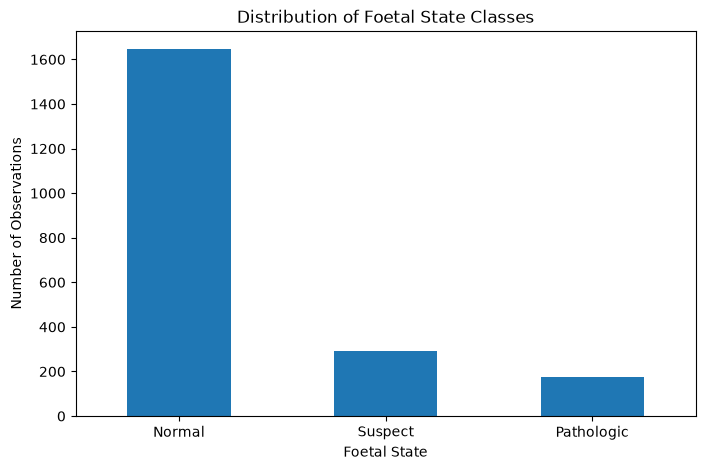

In [46]:
NSP_class_labels = ['Normal', 'Suspect', 'Pathologic']

NSP_class_counts.plot(kind='bar', figsize=(8, 5))

plt.title('Distribution of Foetal State Classes')
plt.xlabel('Foetal State')
plt.ylabel('Number of Observations')
plt.xticks(
    ticks=[0, 1, 2],
    labels=NSP_class_labels,
    rotation=0
)
plt.show()

The target variable is imbalanced, with 77.9% of observations classified as Normal. A model that always predicts Normal would achieve about 78% accuracy, accuracy alone can be misleading. Therefore, recall and F1 scores should also be examined for each class, particularly the Pathologic class. Stratified splitting is needed to maintain similar class proportions across subsets, especially when the test set contains only 5% of the data.

#### 2.2 Predictor variables summary and distributions

In [58]:
# Summary statistics of the 21 features

df_clean[features].describe().T

,count,mean,std,min,25%,50%,75%,max
LB,2111.0,133.312174,9.830875,106.0,126.000000,133.000000,140.000000,160.000000
AC,2111.0,0.003184,0.003865,0.0,0.000000,0.001658,0.005650,0.019284
FM,2111.0,0.009529,0.046829,0.0,0.000000,0.000000,0.002527,0.480634
UC,2111.0,0.004379,0.002936,0.0,0.001928,0.004517,0.006536,0.014925
DL,2111.0,0.001893,0.002967,0.0,0.000000,0.000000,0.003276,0.015385
DS,2111.0,0.000004,0.000063,0.0,0.000000,0.000000,0.000000,0.001353
DP,2111.0,0.000156,0.000580,0.0,0.000000,0.000000,0.000000,0.005348
ASTV,2111.0,47.021317,17.183234,12.0,32.000000,49.000000,61.000000,87.000000
MSTV,2111.0,1.334865,0.884820,0.2,0.700000,1.200000,1.700000,7.000000
ALTV,2111.0,9.799147,18.346595,0.0,0.000000,0.000000,11.000000,91.000000


The 21 features are vary greatly in scale. Heart-rate measures such as LB, Mode, Mean and Median, range from about 60 to 190 beats per minute, while the event rates (AC, FM, UC, DL, DS and DP) are mostly below 0.02 events per second. For several features, such as DS, DP, FM and ALTV, the median is 0 and the maximum is much higher than the upper quartile, show right-skewed distributions.

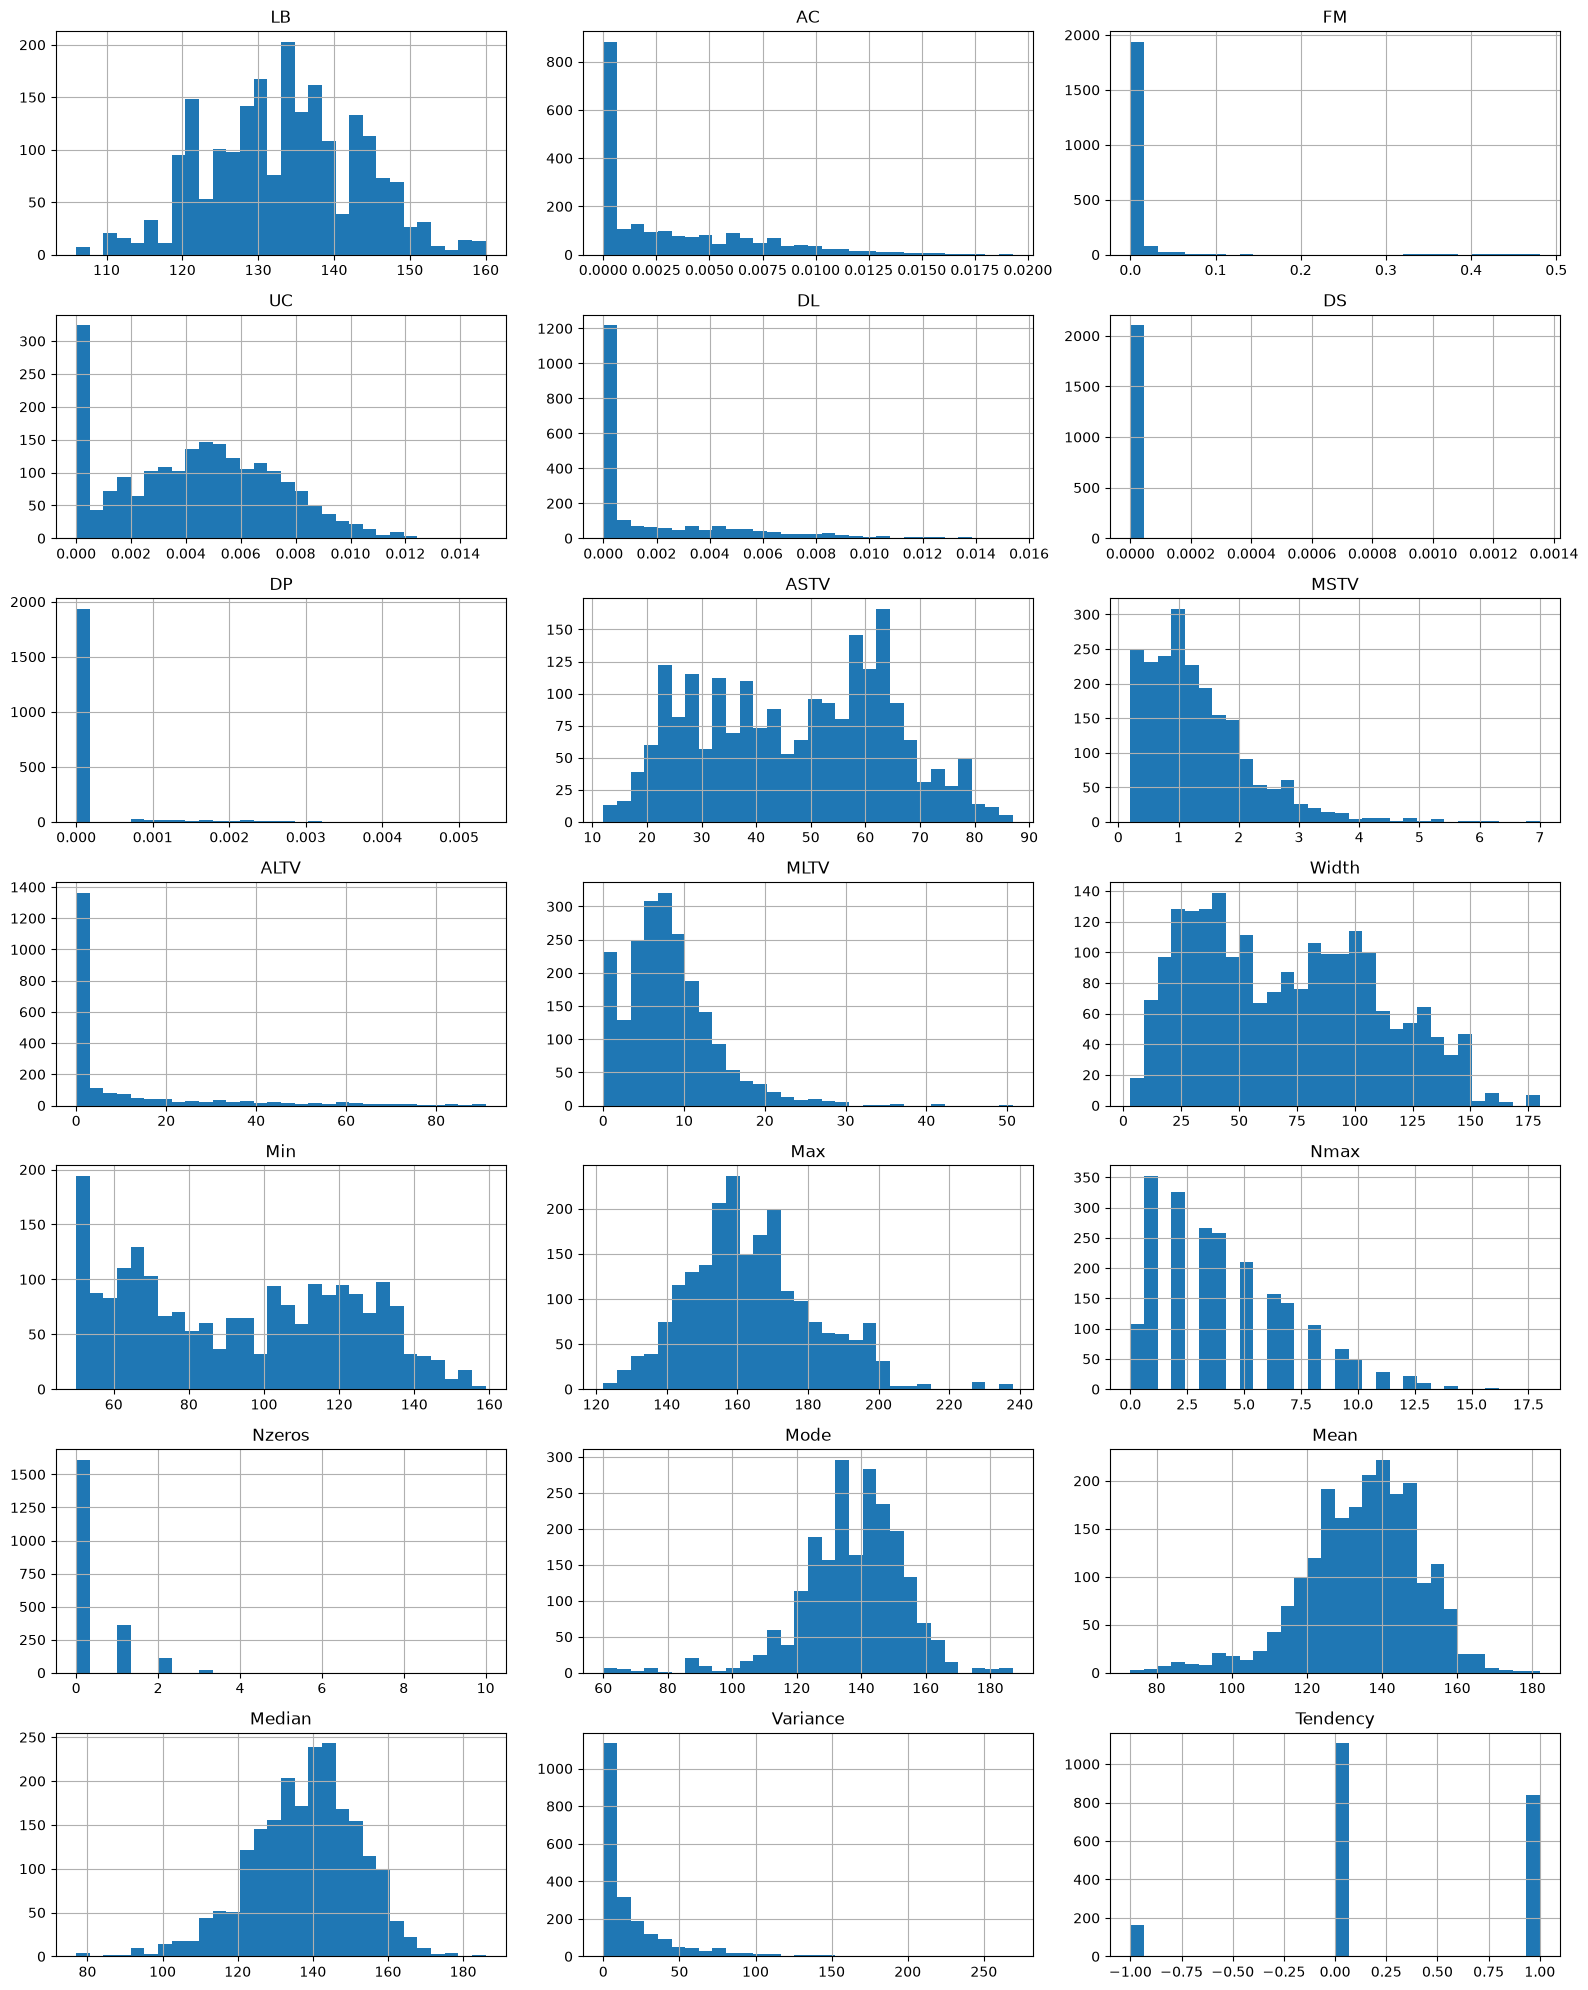

In [57]:
# Histograms of the 21 features

df_clean[features].hist(bins=30, figsize=(16, 20), layout=(7, 3))
plt.tight_layout()
plt.show()

The histograms show three main distribution patterns. Event-related features such as DS, DP, FM, DL and AC are concentrated at zero and have long right tails, which is consistent with many segments containing no recorded events. LB and ASTV are roughly symmetric, while Mode, Mean and Median show slight left skewness due to a small number of low values. These extreme values are real measurements rather than recording errors, so they will be kept.

In [59]:
# Skewness of each feature

skewness = df_clean[features].skew().round(2).sort_values(ascending=False)

skewness

DS          17.75
FM           7.78
DP           4.30
Nzeros       3.91
Variance     3.22
ALTV         2.21
DL           1.72
MSTV         1.66
MLTV         1.35
AC           1.20
Nmax         0.89
Max          0.58
Width        0.31
UC           0.15
Min          0.12
LB           0.02
ASTV        -0.01
Tendency    -0.31
Median      -0.48
Mean        -0.66
Mode        -1.00
dtype: float64

Ten of the 21 features have an absolute skewness values above 1, with the highest values observed for DS (17.75), FM (7.78) and DP (4.3). This shows that several predictor variables have stronly non-symmetric distributions, which is also visible in the histograms.

#### 2.3 Selected predictors by foetal state

To identify which features differ across the three foetal states, a Kruskal-Wallis test was applied to each feature. Kruskal-Wallis compares several independent groups and uses ranks rather than the raw values, and doesn't require normally distributed data. This suits the dataset, as section 2.2 showed that many features are strongly skewed and the three classes are very different in size.

In [65]:
# Kruskal-Wallis test: does each feature differ across the three NSP groups?
kw_results = []

for feature in features:
    group_1 = df_clean.loc[df_clean['NSP'] == 1, feature]
    group_2 = df_clean.loc[df_clean['NSP'] == 2, feature]
    group_3 = df_clean.loc[df_clean['NSP'] == 3, feature]
    
    H_stat, p_value = kruskal(group_1, group_2, group_3)

    kw_results.append({
        'Feature': feature,
        'H Statistic': H_stat,
        'p-value': p_value
    })

kw_results = pd.DataFrame(kw_results)

kw_results = kw_results.sort_values(
    by='H Statistic',
    ascending=False
).reset_index(drop=True)

kw_results['Significant (p < 0.05)'] = kw_results['p-value'] < 0.05

kw_results

,Feature,H Statistic,p-value,Significant (p < 0.05)
0,DP,548.754068,6.911435e-120,True
1,ASTV,530.571544,6.135545e-116,True
2,ALTV,492.487635,1.142007e-107,True
3,AC,449.614472,2.330547e-98,True
4,MSTV,380.042936,2.983493e-83,True
5,Mean,304.410200,7.909788e-67,True
6,Median,295.458295,6.950985e-65,True
7,Mode,269.697942,2.727948e-59,True
8,LB,252.716091,1.328612e-55,True
9,Variance,229.489445,1.468927e-50,True


All 21 features show a statistically significant difference between the three classes (p<0.05), so the H statistica is used to compare their strength. DP, ASTV, ALTV, AC and MSTV have the largest H values, indicate that prolonged decelerations, abnormal variability and accelerations differ most between Normal, Suspect and Pathologic segments. Max, Nzeros and FM have the smallest H values and are the least useful for separating the classes.

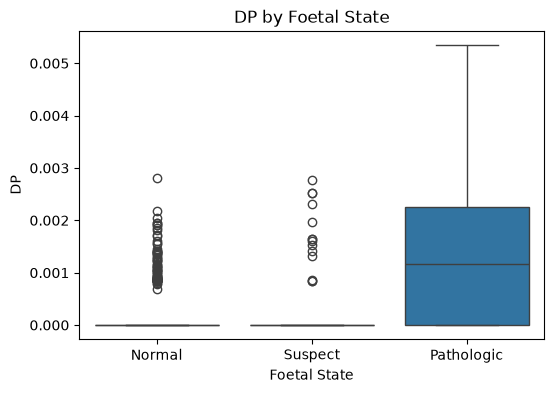

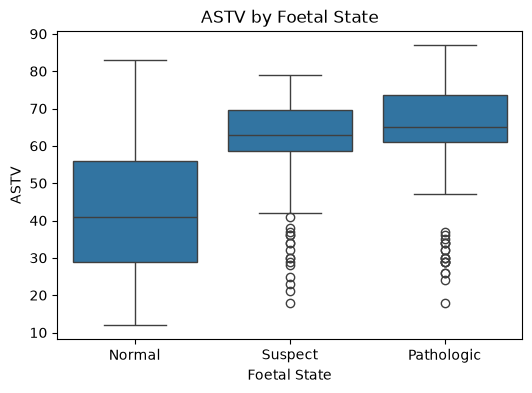

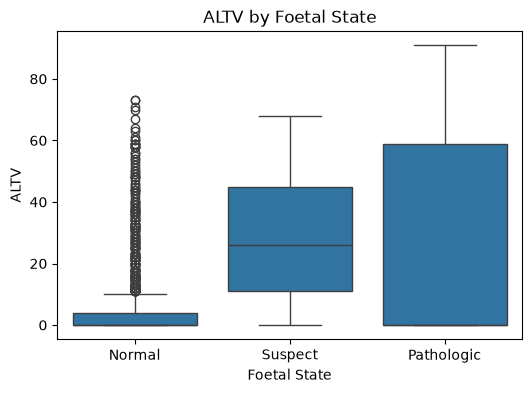

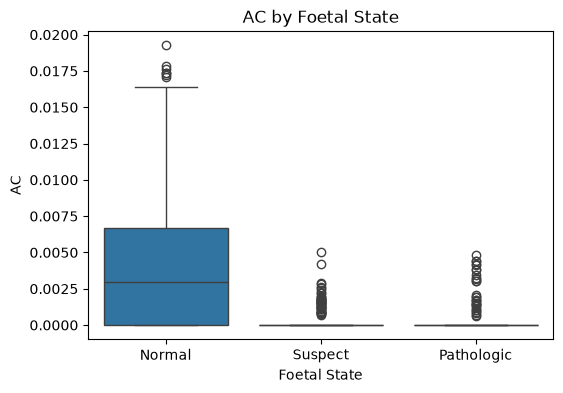

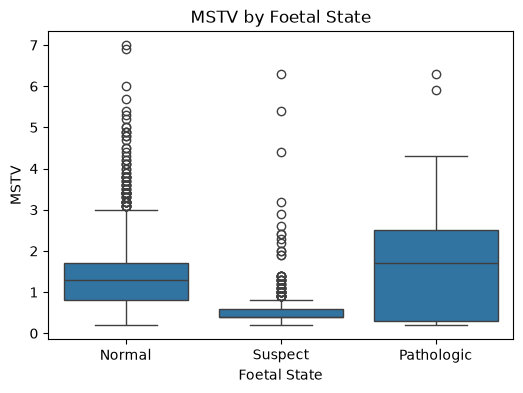

In [71]:
# Boxplots of selected features by foetal state

selected = kw_results['Feature'].head(5)

for feature in selected:
    plt.figure(figsize=(6, 4))
    sns.boxplot(data=df_clean, x='NSP', y=feature)
    plt.title(f'{feature} by Foetal State')
    plt.xlabel('Foetal State')
    plt.xticks([0, 1, 2], ['Normal', 'Suspect', 'Pathologic'])
    plt.show()


DP is mostly zero in Normal and Suspect segments but clearly higher in Pathologic segments, while AC is generally higher in Normal segments.

ASTV is higher in both Suspect and Pathologic segments than in Normal segments, and the two abnormal classes overlap widely.

MSTV is lowest in Suspect segments, while the Pathologic segment has a higher median and a wider distribution. 

This shows that predictor values do not consistently increase with severity. No single feature fully separates all thredd classes, and a combination of features is needed for classification.

#### 2.4 Correlation analysis

2.5 Statistical comparison of selected features

## 5. Split loop

## 6. GridSearchCV

## 7. Evaluation

## 8. Feature Importance

## 9. Summary

Multiple segments originate from the same CTG recording. The main analysis uses stratified random train-test splits rather than recording-level group splits, so segments from the same recording may appear in both training and test sets. This may lead to some dependence between the training and test data and should be considered when interpreting model generalisation.

The 2,126 segments were derived from only 352 original CTG recordings, with up to 34 segments per recording. Because the data were split at segment level, segments from the same recording could appear in both training and test sets, so the reported accuracy is likely to be optimistic for unseen patients. A group-based split by recording (e.g. GroupKFold) would give a more realistic estimate.